# Задание IV. Задача извне

Рассмотрим сеть резервуаров, соединённых трубами. Вода постоянно поступает в один резервуар и уходит через другой.
Нужно найти установившиеся уровни воды: такие, при которых в каждом резервуаре приток равен оттоку.

Сначала составим систему линейных уравнений, затем решим её для разных точек подачи воды.
После этого добавим устройство, поддерживающее заданную разность уровней.

## Устройство сети

Резервуары $0,1,\ldots,20$ соединены последовательно. Труба $i$ соединяет резервуары $i-1$ и $i$. Задайте коэффициенты

$$
g_i=10^{-3+4(i-1)/19},\qquad i=1,\ldots,20
$$

Чем больше $g_i$, тем больше воды проходит по трубе при той же разности уровней.
Все величины будем считать заданными в согласованных условных единицах.

Обозначим через $h_i$ уровень воды относительно уровня в резервуаре 0, который поддерживается постоянным: $h_0=0$.
Остальные $h_i$ неизвестны и могут быть как положительными, так и отрицательными.
Используйте следующую линейную модель:

- Поток из резервуара $i$ в соседний резервуар $j$ равен $g(h_i-h_j)$, где $g$ $\text{---}$ коэффициент соединяющей их трубы.
  Поток показывает объём воды за единицу времени. Отрицательный знак означает движение в обратную сторону.
- В установившемся состоянии сумма потоков из резервуара по трубам равна подаче воды в него извне.

В режиме $j=1,\ldots,10$ вода подаётся только в резервуар $j$ с постоянным потоком $Q=10^{-3}$ и уходит из сети через резервуар 0.

**Nota Bene.**

Баланс воды даёт линейное уравнение относительно уровней. Для внутреннего резервуара $i$:

$$
g_i(h_i-h_{i-1})+g_{i+1}(h_i-h_{i+1})=f_i
$$

Здесь $f_i$ $\text{---}$ внешняя подача воды. У последнего резервуара только одна труба, поэтому в его балансе остаётся одно слагаемое.

## Матрица Кирхгофа

Все балансы можно собрать в одну матрицу $K$, называемую матрицей Кирхгофа.
Начните с нулевой матрицы размера $21\times21$, индексируя строки и столбцы от 0 до 20.
Для каждой трубы между резервуарами $a$ и $b$ с коэффициентом $g$ добавьте:

$$
K_{aa}\mathrel{+}=g,\qquad K_{bb}\mathrel{+}=g,\qquad
K_{ab}\mathrel{-}=g,\qquad K_{ba}\mathrel{-}=g
$$

На диагонали стоят суммы коэффициентов труб каждого резервуара, вне диагонали $\text{---}$ коэффициенты соединяющих труб со знаком минус.
Если трубы нет, соответствующий элемент равен нулю.
При умножении $K$ на вектор уровней каждая компонента результата равна суммарному потоку из соответствующего резервуара по трубам.

Уровень $h_0=0$ известен. Удалите из $K$ строку и столбец с индексом 0.
Полученная матрица $\widehat K$ называется редуцированной матрицей Кирхгофа. Для неизвестных уровней получаем

$$
\widehat Kh=f^{(j)},\qquad
h=\begin{bmatrix}h_1&\cdots&h_{20}\end{bmatrix}^{\top},\qquad
f^{(j)}=Qe_j
$$

Матрица $\widehat K$ описывает трубы. Правая часть задаёт точку и величину подачи воды.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from numpy.typing import NDArray

for _cand in (Path.cwd() / "src", Path.cwd().parent / "src", Path("src")):
    if _cand.is_dir():
        sys.path.insert(0, str(_cand.resolve()))
        break

from decomps.ldlt import ldlt_factor
from decomps.lup import lup_factor
from metrics import backward_error_1, condition_1_estimate, relative_error
from solvers.ldlt_solve import ldlt_solve
from solvers.lup_solve import lup_solve

RESERVOIRS = 20
INFLOW = 1e-3
LEVEL_DIFFERENCE = 5.0
MODES = range(1, 11)
g: NDArray = 10.0 ** (-3 + 4 * np.arange(RESERVOIRS) / (RESERVOIRS - 1))

In [2]:
def text_table(headers, rows):
    columns = [[str(h)] + [str(row[j]) for row in rows] for j, h in enumerate(headers)]
    widths = [max(len(cell) for cell in column) for column in columns]

    lines = []
    for i in range(len(rows) + 1):
        values = [
            column[i].ljust(w) if j == 0 else column[i].rjust(w)
            for j, (column, w) in enumerate(zip(columns, widths))
        ]
        lines.append("  ".join(values))
    lines.insert(1, "  ".join("-" * w for w in widths))
    return "\n".join(lines)

## 1. Составление системы.

Постройте $\widehat K$ по указанному правилу.
Выпишите её первую, внутреннюю и последнюю строки и сопоставьте их с балансами воды.
Докажите, что $\widehat K$ симметрична и положительно определена.
Для этого положите $z_0=0$ и выразите $z^{\top}\widehat Kz$ через квадраты разностей $z_i-z_{i-1}$.
Выберите подходящее разложение и обоснуйте выбор.


In [3]:
def build_kirchhoff(g: NDArray) -> NDArray:
    n = len(g) + 1
    K: NDArray = np.zeros((n, n))
    for i in range(1, n):
        a, b = i - 1, i
        K[a, a] += g[i - 1]
        K[b, b] += g[i - 1]
        K[a, b] -= g[i - 1]
        K[b, a] -= g[i - 1]
    return K


K: NDArray = build_kirchhoff(g)
K_hat: NDArray = K[1:, 1:]
print("Размер K:", K.shape, "размер K_hat:", K_hat.shape)

Размер K: (21, 21) размер K_hat: (20, 20)


In [4]:
def show_row(i: int) -> None:
    """Строка K_hat для резервуара i (в K_hat у него индекс i - 1)."""
    row: NDArray = K_hat[i - 1]
    nonzero: NDArray[np.intp] = np.nonzero(row)[0]
    print(f"Резервуар {i}: ненулевые элементы в столбцах (резервуары) {nonzero + 1}")
    values = ", ".join(f"{value:.4e}" for value in row[nonzero])
    print(f"  значения: [{values}]")


for i in [1, 10, RESERVOIRS]:
    show_row(i)

print()
print(f"g_1 + g_2   = {g[0] + g[1]:.4e},   -g_2  = {-g[1]:.4e}")
print(
    f"-g_10 = {-g[9]:.4e},   g_10 + g_11 = {g[9] + g[10]:.4e},   -g_11 = {-g[10]:.4e}"
)
print(f"-g_20 = {-g[19]:.4e},   g_20 = {g[19]:.4e}")

Резервуар 1: ненулевые элементы в столбцах (резервуары) [1 2]
  значения: [2.6238e-03, -1.6238e-03]
Резервуар 10: ненулевые элементы в столбцах (резервуары) [ 9 10 11]
  значения: [-7.8476e-02, 2.0590e-01, -1.2743e-01]
Резервуар 20: ненулевые элементы в столбцах (резервуары) [19 20]
  значения: [-1.0000e+01, 1.0000e+01]

g_1 + g_2   = 2.6238e-03,   -g_2  = -1.6238e-03
-g_10 = -7.8476e-02,   g_10 + g_11 = 2.0590e-01,   -g_11 = -1.2743e-01
-g_20 = -1.0000e+01,   g_20 = 1.0000e+01


Первая, внутренняя и последняя строки имеют вид

$$
\begin{aligned}
(g_1+g_2)h_1-g_2h_2&=f_1,\\
-g_ih_{i-1}+(g_i+g_{i+1})h_i-g_{i+1}h_{i+1}&=f_i,\quad i=2,\ldots,19,\\
-g_{20}h_{19}+g_{20}h_{20}&=f_{20}.
\end{aligned}
$$

Они совпадают с балансами, потому что слева записаны потоки из каждого резервуара с учётом $h_0=0$ и одной трубы у последнего резервуара.
Матрица симметрична, потому что каждая труба даёт одинаковые элементы в позициях $K_{ab}$ и $K_{ba}$, а удаляются строка и столбец с одним номером.

При $z_0=0$

$$
z^\top\widehat Kz=\sum_{i=1}^{20}g_i(z_i-z_{i-1})^2>0\quad\text{для }z\ne0,
$$

потому что все $g_i>0$, а равенство всех разностей нулю вместе с $z_0=0$ потребовало бы $z=0$.
Выбираем LDLT, потому что оно использует симметрию, а положительные ведущие миноры гарантируют $d_k>0$ без перестановок.


In [5]:
print("K_hat симметрична:", np.array_equal(K_hat, K_hat.T))

L, d = ldlt_factor(K_hat)
print(f"min d_k = {d.min():.4e},  max d_k = {d.max():.4e}")
print(f"все d_k > 0: {np.all(d > 0)}")
print(f"max |l_ik| = {np.abs(L).max():.4e}")

K_hat симметрична: True
min d_k = 3.8418e-04,  max d_k = 1.0000e+01
все d_k > 0: True
max |l_ik| = 1.0000e+00


## 2. Режимы работы.

Постройте разложение $\widehat K$ один раз и найдите уровни для всех десяти правых частей $f^{(j)}$.
По найденным уровням вычислите потоки из резервуара $i$ в резервуар $i-1$:

$$
\varphi_i=g_i(h_i-h_{i-1})
$$

Проверьте балансы. Выведите точную формулу уровней: от точки подачи до резервуара 0 по каждой трубе проходит поток $Q$, а в остальных трубах поток равен нулю.
Сравните численное решение с формулой и вычислите $\eta_{\mathrm{back},1}$.
При сборке $\widehat K$, проверке потоков и подстановке в формулу используйте одни и те же вычисленные $g_i$.
Значения формулы в `float64` также содержат ошибки округления.
Постройте графики уровней для $j=1$ и $j=10$, включая резервуар 0.


Через трубы $1,\ldots,j$ проходит поток $Q$, через трубы правее $j$ $\text{---}$ нулевой, потому что вся поданная вода уходит через резервуар 0.
Из $g_i(h_i-h_{i-1})=Q$ при $i\le j$ и $h_0=0$ получаем

$$
h_i=\sum_{l=1}^{\min(i,j)}\frac{Q}{g_l},\qquad i=1,\ldots,20.
$$


In [6]:
def inflow(j: int) -> NDArray:
    f: NDArray = np.zeros(RESERVOIRS)
    f[j - 1] = INFLOW
    return f


def exact_levels(j: int) -> NDArray:
    drops: NDArray = np.cumsum(INFLOW / g)
    h: NDArray = np.empty(RESERVOIRS)
    h[:j] = drops[:j]
    h[j:] = drops[j - 1]
    return h


def flows(h: NDArray) -> NDArray:
    """phi_i = g_i (h_i - h_{i-1}), i = 1..20, h_0 = 0."""
    levels: NDArray = np.concatenate(([0.0], h))
    return g * (levels[1:] - levels[:-1])


solutions: dict[int, NDArray] = {}
rows = []
for j in MODES:
    f: NDArray = inflow(j)
    h: NDArray = ldlt_solve(L, d, f)
    solutions[j] = h
    phi: NDArray = flows(h)
    flow_balance: NDArray = phi - np.concatenate((phi[1:], [0.0]))
    assert np.allclose(flow_balance, f, rtol=0, atol=1e-13)
    balance = np.linalg.norm(K_hat @ h - f, np.inf)
    upstream = np.abs(phi[:j] - INFLOW).max()
    downstream = np.abs(phi[j:]).max()
    rows.append(
        [
            str(j),
            f"{balance:.3e}",
            f"{upstream:.3e}",
            f"{downstream:.3e}",
            f"{relative_error(h, exact_levels(j)):.3e}",
            f"{backward_error_1(K_hat, h, f):.3e}",
        ]
    )
print(
    text_table(
        [
            "j",
            "||Kh - f||_inf",
            "max|phi - Q|, i<=j",
            "max|phi|, i>j",
            "отн. ошибка",
            "eta_back,1",
        ],
        rows,
    )
)

j   ||Kh - f||_inf  max|phi - Q|, i<=j  max|phi|, i>j  отн. ошибка  eta_back,1
--  --------------  ------------------  -------------  -----------  ----------
1        2.776e-17           1.521e-15      1.916e-15    3.694e-12   5.133e-20
2        3.553e-15           2.458e-15      2.875e-15    3.752e-12   4.018e-18
3        7.105e-15           3.035e-15      3.833e-15    3.799e-12   7.268e-18
4        7.105e-15           3.390e-15      4.472e-15    3.837e-12   1.666e-17
5        3.553e-15           3.609e-15      5.110e-15    3.869e-12   6.228e-18
6        7.105e-15           3.743e-15      4.472e-15    3.893e-12   7.531e-18
7        8.882e-16           3.827e-15      5.110e-15    3.911e-12   1.100e-18
8        8.882e-16           3.877e-15      5.110e-15    3.925e-12   5.920e-19
9        3.553e-15           3.920e-15      5.110e-15    3.936e-12   3.922e-18
10       3.553e-15           3.942e-15      4.472e-15    3.944e-12   4.423e-18


In [7]:
kappa = condition_1_estimate(K_hat, lambda b: ldlt_solve(L, d, b))
u_round = np.finfo(np.float64).eps / 2
print(f"kappa~_1(K_hat) = {kappa:.4e}")
print(f"u * kappa~_1    = {u_round * kappa:.4e}")

kappa~_1(K_hat) = 1.5477e+06
u * kappa~_1    = 1.7182e-10


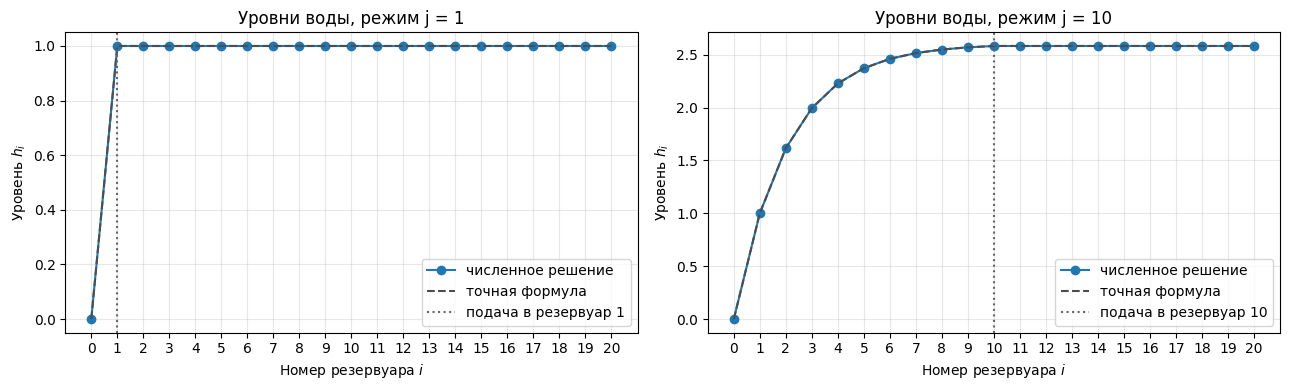

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
reservoirs: NDArray = np.arange(RESERVOIRS + 1)

for ax, j in zip(axes, (1, 10)):
    h_num: NDArray = np.concatenate(([0.0], solutions[j]))
    h_exact: NDArray = np.concatenate(([0.0], exact_levels(j)))
    ax.plot(reservoirs, h_num, "o-", label="численное решение")
    ax.plot(reservoirs, h_exact, "--", color="0.3", label="точная формула")
    ax.axvline(j, color="0.4", linestyle=":", label=f"подача в резервуар {j}")
    ax.set_title(f"Уровни воды, режим j = {j}")
    ax.set_xlabel("Номер резервуара $i$")
    ax.set_ylabel("Уровень $h_i$")
    ax.set_xticks(reservoirs)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

Все десять режимов решены с одним разложением $\widehat K$.
Невязки балансов имеют порядок $10^{-15}$, ошибки потоков меньше $10^{-14}$, обратная погрешность меньше $2\cdot10^{-17}$.
Расхождение с формулой уровней составляет около $4\cdot10^{-12}$ и включает округления при вычислении самой формулы.
Уровни растут до точки подачи и далее постоянны, потому что разности соседних уровней равны $Q/g_i$ до неё и нулю после.


## Заданная разность уровней

Пусть вода подаётся в резервуар 10 с потоком $Q=10^{-3}$, как в режиме $j=10$ предыдущей части.
Между резервуарами 1 и 20 установим устройство, которое перекачивает воду так, чтобы поддерживать

$$
h_1-h_{20}=5
$$

Поток через устройство заранее неизвестен.
Обозначим его через $s$, считая положительным направление от резервуара 1 к резервуару 20.

**Nota Bene.**

В балансе резервуара 1 появляется слагаемое $+s$, а в балансе резервуара 20 $\text{---}$ слагаемое $-s$.
Введём $c=e_1-e_{20}$. Тогда изменённые балансы и условие на уровни имеют вид

$$
\widehat Kh+cs=f^{(10)},\qquad c^{\top}h=5
$$

Теперь неизвестны двадцать уровней и один дополнительный поток.
Условие на разность уровней даёт недостающее уравнение.


## 3. Новая система.

Запишите полученную систему для неизвестных $h_1,\ldots,h_{20},s$ в блочном матричном виде через $\widehat K$ и $c$.
Определите, какие из трёх реализованных разложений применимы при этом порядке неизвестных.
Выберите одно и найдите уровни и поток через устройство.
В LDLT выбор ведущего элемента не делается.
Покажите, что для SPD-матрицы $A=LDL^{\top}$ элементы факторов ограничены: из

$$
a_{ii}=\sum_j l_{ij}^2d_j
$$

следуют

$$
d_k\le a_{kk},\qquad |l_{ik}|\sqrt{d_k}\le\sqrt{a_{ii}}
$$

Есть ли такая гарантия для новой системы?


Для неизвестных $h_1,\ldots,h_{20},s$ получаем

$$
H\begin{bmatrix}h\\s\end{bmatrix}=\begin{bmatrix}f^{(10)}\\5\end{bmatrix},\qquad
H=\begin{bmatrix}\widehat K&c\\c^\top&0\end{bmatrix}.
$$

Применимы все три разложения: LUP и QR дают решение, потому что $H$ невырождена:

$$
\det H=\det\widehat K\cdot(-c^\top\widehat K^{-1}c)\ne0,\qquad c^\top\widehat K^{-1}c>0.
$$

LDLT без перестановок существует, потому что $H$ симметрична, первые двадцать ведущих миноров совпадают с положительными минорами $\widehat K$, а полный определитель ненулевой.
Выбираем LDLT, потому что оно использует симметрию этой системы.

Для SPD-матрицы $A=LDL^\top$ все $d_j>0$, поэтому из

$$
a_{ii}=\sum_{j<i}l_{ij}^2d_j+d_i
$$

каждое слагаемое не превосходит $a_{ii}$, значит,

$$
d_i\le a_{ii},\qquad |l_{ik}|\sqrt{d_k}\le\sqrt{a_{ii}}.
$$


In [9]:
c: NDArray = np.zeros(RESERVOIRS)
c[0], c[-1] = 1.0, -1.0
f10: NDArray = inflow(10)

H: NDArray = np.block([[K_hat, c[:, None]], [c[None, :], np.zeros((1, 1))]])
rhs: NDArray = np.concatenate((f10, [LEVEL_DIFFERENCE]))

L_H, d_H = ldlt_factor(H)

schur = -c @ ldlt_solve(L, d, c)
print(f"d_21 = {d_H[-1]:.6e},   -c^T K_hat^(-1) c = {schur:.6e}")
print(f"d_1..d_20 > 0: {np.all(d_H[:-1] > 0)},   d_21 < 0: {d_H[-1] < 0}")
print()

print("Оценки для SPD-части (строки 1..20):")
diag: NDArray = np.diag(H)
print(f"  d_k <= a_kk: {np.all(d_H[:-1] <= diag[:-1])}")
bound: NDArray = np.abs(L_H[:-1, :-1]) * np.sqrt(d_H[:-1])
print(
    f"  max_ik |l_ik| sqrt(d_k) / sqrt(a_ii) = "
    f"{np.max(bound / np.sqrt(diag[:-1, None])):.4f}"
)
print()

print("Последняя строка (уравнение c^T h = 5):")
last: NDArray = np.abs(L_H[-1, :-1]) * np.sqrt(d_H[:-1])
print(f"  a_21,21 = {diag[-1]:.1f}")
print(f"  max_k |l_21,k| sqrt(d_k) = {last.max():.4e}")
print(f"  max_k |l_21,k|           = {np.abs(L_H[-1]).max():.4e}")

d_21 = -1.602977e+03,   -c^T K_hat^(-1) c = -1.602977e+03
d_1..d_20 > 0: True,   d_21 < 0: True

Оценки для SPD-части (строки 1..20):
  d_k <= a_kk: True
  max_ik |l_ik| sqrt(d_k) / sqrt(a_ii) = 1.0000

Последняя строка (уравнение c^T h = 5):
  a_21,21 = 0.0
  max_k |l_21,k| sqrt(d_k) = 3.1419e+01
  max_k |l_21,k|           = 1.6030e+03


Нет, для новой системы такой гарантии нет, потому что $d_{21}=-c^\top\widehat K^{-1}c\approx-1603$ отрицательно и компенсирует положительные слагаемые в равенстве

$$
a_{21,21}=0=\sum_{j=1}^{20}l_{21,j}^2d_j+d_{21}.
$$

В расчёте $\max_k|l_{21,k}|\sqrt{d_k}\approx31.4>\sqrt{a_{21,21}}=0$, поэтому оценка для SPD-матрицы здесь нарушается.


## 4. Проверка результата.

Вычислите невязку балансов $\widehat Kh+cs-f^{(10)}$, отклонение $h_1-h_{20}-5$ и обратную погрешность $\eta_{\mathrm{back},1}$ всей системы.
Объясните, в какую сторону устройство перекачивает воду, и сравните уровни с режимом $j=10$ до его подключения.
Укажите, что меняется в системе при переносе точки подачи воды и при добавлении устройства.
В каком случае можно использовать прежнее разложение?


In [10]:
solution: NDArray = ldlt_solve(L_H, d_H, rhs)
h_dev, s = solution[:-1], solution[-1]

L_P, U_P, p_P = lup_factor(H)
solution_lup: NDArray = lup_solve(L_P, U_P, p_P, rhs)

print(f"s = {s:.6e}")
print(
    f"||K_hat h + c s - f||_inf = {np.linalg.norm(K_hat @ h_dev + c * s - f10, np.inf):.3e}"
)
print(f"h_1 - h_20 - 5           = {h_dev[0] - h_dev[-1] - LEVEL_DIFFERENCE:.3e}")
print(f"eta_back,1 (вся система) = {backward_error_1(H, solution, rhs):.3e}")
print(f"отличие от LUP           = {relative_error(solution_lup, solution):.3e}")

s = -4.106552e-03
||K_hat h + c s - f||_inf = 7.105e-15
h_1 - h_20 - 5           = -8.882e-16
eta_back,1 (вся система) = 4.354e-18
отличие от LUP           = 2.278e-12


In [11]:
h_before: NDArray = solutions[10]
phi_before, phi_after = flows(h_before), flows(h_dev)
rows = [
    [
        str(i),
        f"{h_before[i - 1]:.4f}",
        f"{h_dev[i - 1]:.4f}",
        f"{phi_before[i - 1]:.3e}",
        f"{phi_after[i - 1]:.3e}",
    ]
    for i in range(1, RESERVOIRS + 1)
]
print(text_table(["i", "h до", "h после", "phi до", "phi после"], rows))

i     h до  h после      phi до   phi после
--  ------  -------  ----------  ----------
1   1.0000   1.0000   1.000e-03   1.000e-03
2   1.6158  -0.9132   1.000e-03  -3.107e-03
3   1.9951  -2.0914   1.000e-03  -3.107e-03
4   2.2287  -2.8170   1.000e-03  -3.107e-03
5   2.3725  -3.2638   1.000e-03  -3.107e-03
6   2.4611  -3.5390   1.000e-03  -3.107e-03
7   2.5157  -3.7085   1.000e-03  -3.107e-03
8   2.5493  -3.8129   1.000e-03  -3.107e-03
9   2.5700  -3.8772   1.000e-03  -3.107e-03
10  2.5827  -3.9168   1.000e-03  -3.107e-03
11  2.5827  -3.9490   3.961e-15  -4.107e-03
12  2.5827  -3.9688   3.951e-15  -4.107e-03
13  2.5827  -3.9811   4.178e-15  -4.107e-03
14  2.5827  -3.9886   4.119e-15  -4.107e-03
15  2.5827  -3.9932   3.934e-15  -4.107e-03
16  2.5827  -3.9961   4.472e-15  -4.107e-03
17  2.5827  -3.9978   4.149e-15  -4.107e-03
18  2.5827  -3.9989   3.369e-15  -4.107e-03
19  2.5827  -3.9996   2.735e-15  -4.107e-03
20  2.5827  -4.0000  -4.441e-15  -4.107e-03


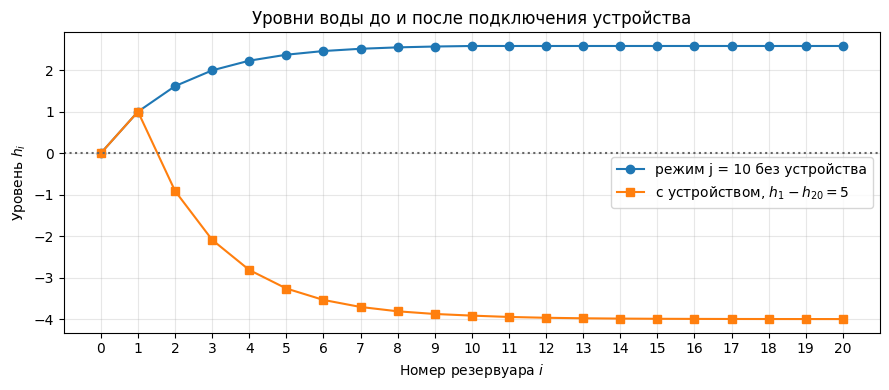

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(
    reservoirs,
    np.concatenate(([0.0], h_before)),
    "o-",
    label="режим j = 10 без устройства",
)
ax.plot(
    reservoirs,
    np.concatenate(([0.0], h_dev)),
    "s-",
    label=r"с устройством, $h_1 - h_{20} = 5$",
)
ax.axhline(0, color="0.4", linestyle=":")
ax.set_title("Уровни воды до и после подключения устройства")
ax.set_xlabel("Номер резервуара $i$")
ax.set_ylabel("Уровень $h_i$")
ax.set_xticks(reservoirs)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

Для устройства прежнее разложение можно использовать через дополнение Шура, потому что после двух решений

$$
\widehat Ky=f^{(10)},\qquad \widehat Kw=c
$$

уровни и поток выражаются как

$$
s=\frac{c^\top y-5}{c^\top w},\qquad h=y-sw.
$$


In [13]:
y: NDArray = ldlt_solve(L, d, f10)
w: NDArray = ldlt_solve(L, d, c)
s_reuse = (c @ y - LEVEL_DIFFERENCE) / (c @ w)
h_reuse: NDArray = y - s_reuse * w

print(f"s через старое разложение = {s_reuse:.6e}")
print(f"отличие h от решения LDLT(H) = {relative_error(h_reuse, h_dev):.3e}")

s_formula = -(LEVEL_DIFFERENCE + INFLOW * np.sum(1 / g[1:10])) / np.sum(1 / g[1:])
phi_formula: NDArray = np.full(RESERVOIRS, s_formula)
phi_formula[:10] += INFLOW
phi_formula[0] = INFLOW
h_formula: NDArray = np.cumsum(phi_formula / g)
print(f"s по балансам потоков = {s_formula:.6e}")
print(f"отличие h от формулы потоков = {relative_error(h_dev, h_formula):.3e}")
assert np.allclose(h_dev, h_formula, rtol=1e-10, atol=1e-11)
assert np.allclose(flows(h_dev), phi_formula, rtol=0, atol=1e-13)
assert abs(h_dev[0] - h_dev[-1] - LEVEL_DIFFERENCE) < 1e-12
assert backward_error_1(H, solution, rhs) < 1e-14

s через старое разложение = -4.106552e-03
отличие h от решения LDLT(H) = 3.610e-16
s по балансам потоков = -4.106552e-03
отличие h от формулы потоков = 1.704e-12


Невязка балансов равна примерно $7.1\cdot10^{-15}$, отклонение условия на уровни $\text{---}$ $9\cdot10^{-16}$, обратная погрешность всей системы $\text{---}$ $4.4\cdot10^{-18}$.

Устройство перекачивает воду из резервуара 20 в резервуар 1, потому что $s\approx-4.1066\cdot10^{-3}$ отрицателен при выбранном положительном направлении от 1 к 20.
Уровень $h_1\approx1$ сохраняется, потому что общий приток $Q$ по-прежнему уходит по первой трубе, а $h_{20}$ уменьшается с $2.58$ до $-4$ по условию $h_1-h_{20}=5$.
Остальные уровни после резервуара 1 убывают, как видно из таблицы и графика.

При переносе точки подачи можно использовать прежнее разложение напрямую, потому что меняется только правая часть $f^{(j)}$.
Добавление устройства расширяет матрицу до $H$, поэтому для решения используем разложение $H$ или приведённое выше исключение через сохранённые факторы $\widehat K$.
